# Atividade Prática 3: Classificação de áudios
* Ana Carolina Saggioratto Osello
* Nº USP: 13683104

## Ambiente e dados

In [12]:
%pip install -q librosa soundfile scikit-learn pandas matplotlib seaborn scipy tqdm

import os
import subprocess
from pathlib import Path
from urllib.request import urlretrieve

PASTA_DADOS = Path("/content/sounds")

def localizar_dataset(pasta):
    return next(
        (p.parent for p in pasta.rglob("COPD")
         if p.is_dir() and (p.parent / "Healthy").is_dir()),
        None,
    )

DATASET_PATH = localizar_dataset(PASTA_DADOS)

if DATASET_PATH is None:
    subprocess.run(["apt-get", "update", "-qq"], check=True)
    subprocess.run(["apt-get", "install", "-y", "-qq", "unrar"], check=True)

    arquivo_rar = Path("/content/COPD-Cough (CC).rar")
    print("Baixando o dataset (549 MB)...")
    urlretrieve(
        "https://zenodo.org/records/10209837/files/COPD-Cough%20(CC).rar?download=1",
        arquivo_rar,
    )
    print("Extraindo os áudios...")
    PASTA_DADOS.mkdir(parents=True, exist_ok=True)
    subprocess.run(
        ["unrar", "x", "-o+", "-idq", str(arquivo_rar), str(PASTA_DADOS) + "/"],
        check=True,
        env={**os.environ, "LANG": "C.UTF-8", "LC_ALL": "C.UTF-8"},
    )
    DATASET_PATH = localizar_dataset(PASTA_DADOS)
    if DATASET_PATH is None:
        raise FileNotFoundError(
            "A extração não criou as pastas COPD e Healthy esperadas."
        )

    arquivo_rar.unlink()
n_wav = sum(1 for _ in DATASET_PATH.rglob("*.wav"))
print("Dataset:", DATASET_PATH)
print("Arquivos .wav encontrados:", n_wav, "(esperado: 853)")
assert n_wav == 853, f"Dataset incompleto ou inesperado: {n_wav} arquivos .wav (esperados: 853)."


Dataset: /content/sounds/COPD-Cough (CC)
Arquivos .wav encontrados: 853 (esperado: 853)


In [13]:
import re
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf
from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, f1_score, recall_score, roc_auc_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from tqdm.auto import tqdm

SEMENTE = 42
SR, N_FFT, HOP = 16000, 512, 160
N_MFCC, N_MELS = 20, 40
# Identidade visual dos gráficos
CORES = {"Saudável": "#287E86", "DPOC": "#C46A52"}
ORDEM_CLASSES = ["Saudável", "DPOC"]
sns.set_theme(
    style="whitegrid",
    context="notebook",
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "semibold",
        "axes.titlesize": 12,
        "axes.labelsize": 10,
        "grid.alpha": 0.22,
        "figure.dpi": 120,
        "savefig.dpi": 180,
    },
)

In [14]:
registros = []
for classe in ["COPD", "Healthy"]:
    for arquivo in sorted((DATASET_PATH / classe).glob("*/*.wav")):
        info = sf.info(arquivo)
        registros.append({
            "arquivo": arquivo,
            "classe": "DPOC" if classe == "COPD" else "Saudável",
            "rotulo": int(classe == "COPD"),
            "participante": classe + "/" + arquivo.parent.name,
            "lote": re.sub(r"-?\d+$", "", arquivo.parent.name),
            "data": pd.to_datetime(int(arquivo.name[:13]), unit="ms", utc=True, errors="coerce"),
            "duracao_s": info.duration,
            "sr": info.samplerate,
            "canais": info.channels,
        })
df = pd.DataFrame(registros)
assert not df.empty and (df["duracao_s"] > 0).all()
assert len(df) == n_wav and df["arquivo"].is_unique, "Verifique se todos os áudios foram listados uma única vez."
display(df.groupby("classe").agg(gravacoes=("arquivo", "size"),
                                participantes=("participante", "nunique")))
print("Taxas de amostragem:", sorted(df["sr"].unique()))
print("Número de canais:", sorted(df["canais"].unique()))

,gravacoes,participantes
classe,,
DPOC,221,78
Saudável,632,211


Taxas de amostragem: [np.int64(48000)]
Número de canais: [np.int64(2)]


## Preparação e extração de atributos
Cada áudio é convertido para mono a 16 kHz, normalizado pelo pico e tem os trechos silenciosos removidos (20 dB abaixo do pico). Para sinais muito curtos, mantém-se o áudio completo. Extraem-se média e desvio padrão de 20 MFCC, 20 delta-MFCC, centroide, largura de banda, roll-off e taxa de cruzamento por zero: 88 atributos por gravação. Datas, lotes e identificadores não entram no classificador.

In [15]:
def carregar_audio(arquivo):
    sinal, _ = librosa.load(arquivo, sr=SR, mono=True)
    if len(sinal) == 0 or not np.isfinite(sinal).all() or np.max(np.abs(sinal)) == 0:
        raise ValueError(f"áudio vazio, inválido ou sem sinal: {arquivo}")
    sinal = sinal / np.max(np.abs(sinal))
    intervalos = librosa.effects.split(sinal, top_db=20, frame_length=N_FFT, hop_length=HOP)
    filtrado = np.concatenate([sinal[a:b] for a, b in intervalos]) if len(intervalos) else sinal
    return filtrado if len(filtrado) >= 2 * N_FFT else sinal


def extrair_atributos(arquivo):
    sinal = carregar_audio(arquivo)
    mfcc = librosa.feature.mfcc(y=sinal, sr=SR, n_mfcc=N_MFCC,
                              n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS)
    descritores = {
        "mfcc": mfcc,
        "delta_mfcc": librosa.feature.delta(mfcc, mode="nearest"),
        "centroide": librosa.feature.spectral_centroid(y=sinal, sr=SR, n_fft=N_FFT, hop_length=HOP),
        "largura_banda": librosa.feature.spectral_bandwidth(y=sinal, sr=SR, n_fft=N_FFT, hop_length=HOP),
        "rolloff": librosa.feature.spectral_rolloff(y=sinal, sr=SR, n_fft=N_FFT, hop_length=HOP),
        "zcr": librosa.feature.zero_crossing_rate(sinal, frame_length=N_FFT, hop_length=HOP),
    }
    atributos = {}
    for nome, matriz in descritores.items():
        for i, linha in enumerate(matriz):
            prefixo = f"{nome}_{i + 1}" if len(matriz) > 1 else nome
            atributos[prefixo + "_media"] = linha.mean()
            atributos[prefixo + "_desvio"] = linha.std()
    return atributos

In [16]:
%%time
X = pd.DataFrame([extrair_atributos(a) for a in tqdm(df["arquivo"], desc="Extraindo atributos")])
y = df["rotulo"].to_numpy()
grupos = df["participante"].to_numpy()
assert np.isfinite(X.to_numpy()).all()
print(f"{X.shape[0]} gravações × {X.shape[1]} atributos")

Extraindo atributos:   0%|          | 0/853 [00:00<?, ?it/s]

853 gravações × 88 atributos
CPU times: user 45.4 s, sys: 540 ms, total: 45.9 s
Wall time: 38 s


## Divisão e análise exploratória

Os dados são divididos com `StratifiedGroupKFold`, reservando cerca de 20% para teste. A validação e a padronização são feitas apenas com os dados de treinamento de cada fold.

O agrupamento por pastas evita que gravações da mesma pasta apareçam em conjuntos diferentes, embora não garanta que sejam de pessoas distintas. A análise exploratória utiliza apenas os dados de desenvolvimento.

In [17]:
divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
idx_dev, idx_teste = next(divisor.split(X, y, grupos))
X_dev, X_teste = X.iloc[idx_dev], X.iloc[idx_teste]
y_dev, y_teste = y[idx_dev], y[idx_teste]
g_dev, g_teste = grupos[idx_dev], grupos[idx_teste]
df_dev = df.iloc[idx_dev].reset_index(drop=True)
assert set(g_dev).isdisjoint(g_teste)
folds = list(divisor.split(X_dev, y_dev, g_dev))
for treino, validacao in folds:
    assert set(g_dev[treino]).isdisjoint(g_dev[validacao])
    assert len(np.unique(y_dev[treino])) == len(np.unique(y_dev[validacao])) == 2

display(pd.DataFrame([
    {"conjunto": nome, "classe": classe, "gravações": len(sub),
     "participantes": sub["participante"].nunique()}
    for nome, indices in [("Desenvolvimento", idx_dev), ("Teste", idx_teste)]
    for classe, sub in df.iloc[indices].groupby("classe")
]).set_index(["conjunto", "classe"]))

gravações  participantes
conjunto        classe                            
Desenvolvimento DPOC            178             62
                Saudável        507            170
Teste           DPOC             43             16
                Saudável        125             41

,count,mean,std,min,25%,50%,75%,max
classe,,,,,,,,
DPOC,178.0,8.06,4.20,0.86,6.24,7.29,9.13,36.38
Saudável,507.0,7.25,1.84,3.82,6.18,6.90,7.72,29.92


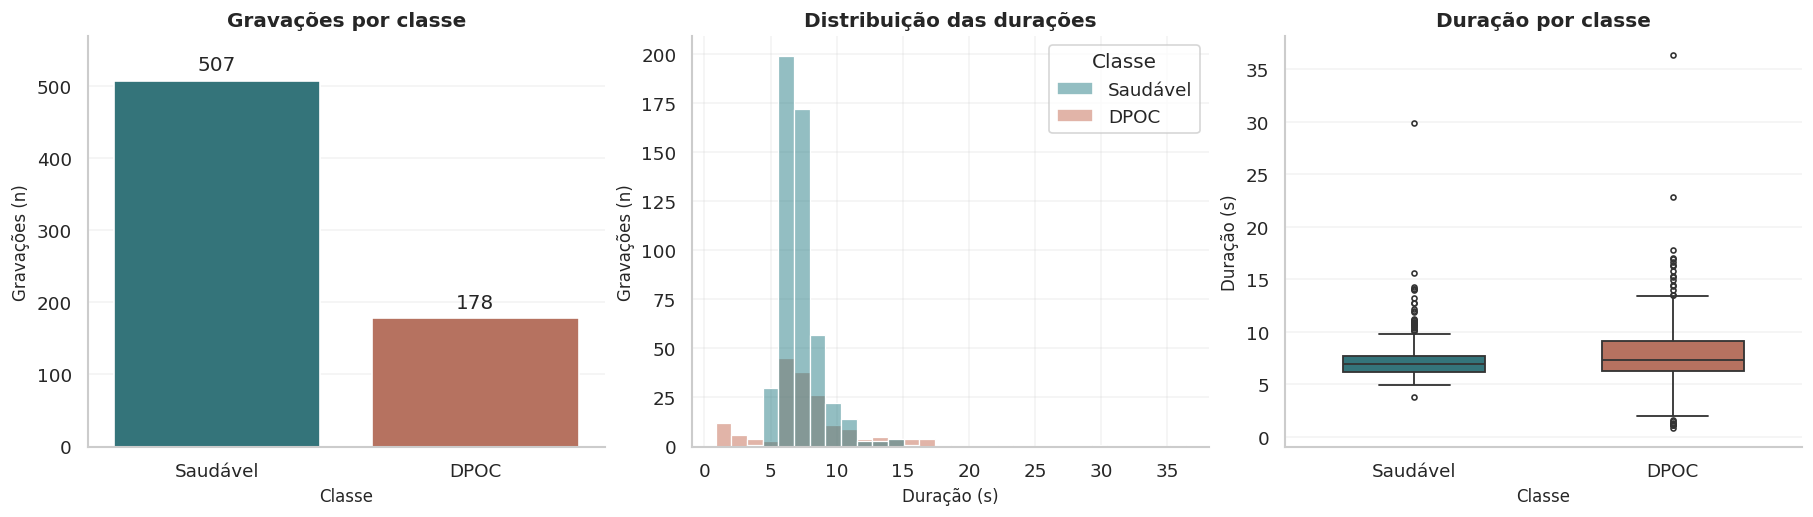

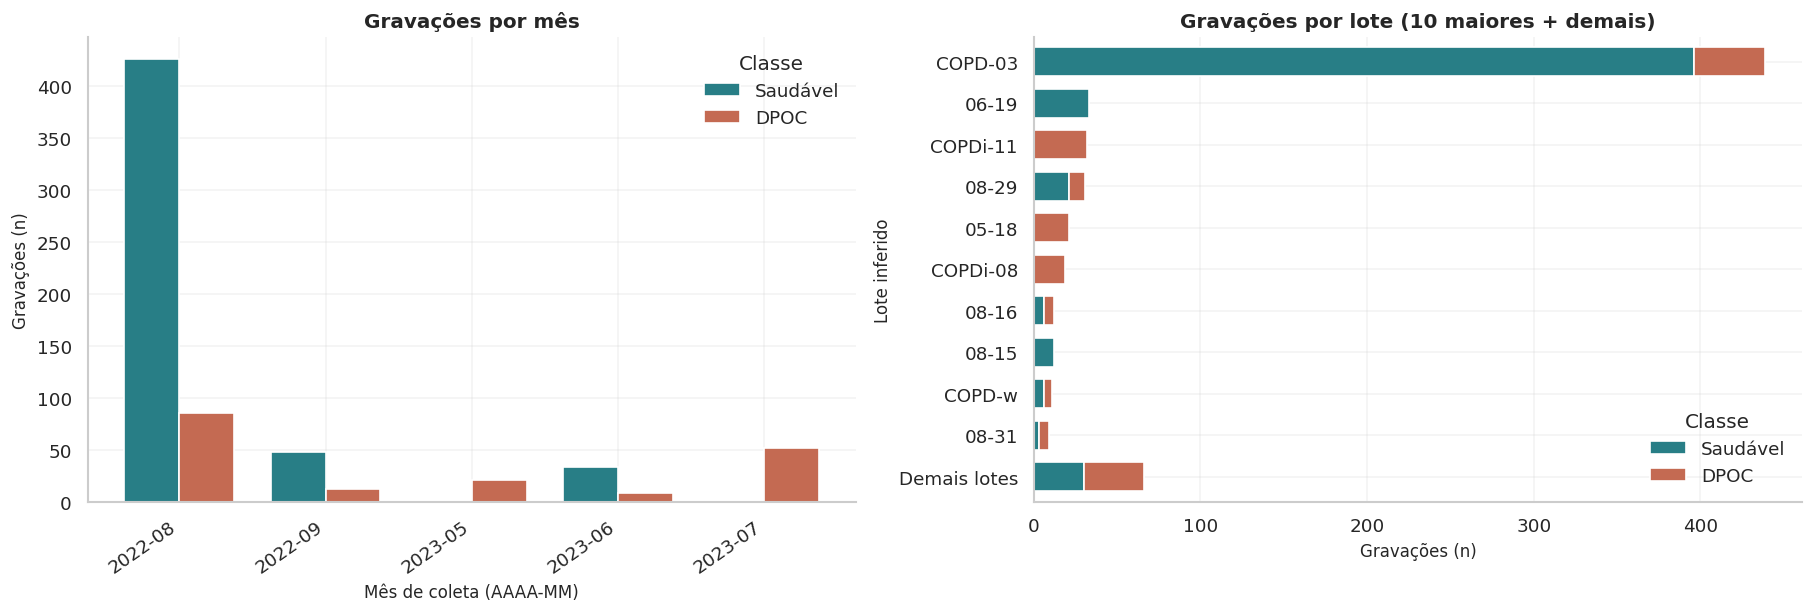

In [18]:
display(df_dev.groupby("classe")["duracao_s"].describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
sns.countplot(data=df_dev, x="classe", hue="classe", order=ORDEM_CLASSES,
              palette=CORES, legend=False, ax=axes[0])
axes[0].set(title="Gravações por classe", xlabel="Classe", ylabel="Gravações (n)")
for barra in axes[0].patches:
    axes[0].annotate(f"{int(barra.get_height())}",
                     (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                     ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")
axes[0].set_ylim(top=axes[0].get_ylim()[1] * 1.07)

sns.histplot(data=df_dev, x="duracao_s", hue="classe", hue_order=ORDEM_CLASSES,
             palette=CORES, bins=30, alpha=0.5, edgecolor="white", ax=axes[1])
axes[1].set(title="Distribuição das durações", xlabel="Duração (s)", ylabel="Gravações (n)")
if axes[1].get_legend():
    axes[1].get_legend().set_title("Classe")

sns.boxplot(data=df_dev, x="classe", y="duracao_s", hue="classe",
            order=ORDEM_CLASSES, palette=CORES, legend=False, width=0.55,
            fliersize=3, linewidth=1.1, ax=axes[2])
axes[2].set(title="Duração por classe", xlabel="Classe", ylabel="Duração (s)")
plt.show()

# A visualização mensal usa os mesmos dados da tabela de contingência original.
meses = pd.crosstab(df_dev["data"].dt.strftime("%Y-%m"), df_dev["classe"])
meses = meses.reindex(columns=ORDEM_CLASSES, fill_value=0)

# Nos lotes, exibe-se os 10 maiores e agregamos os demais para evitar rótulos ilegíveis.
lotes = pd.crosstab(df_dev["lote"], df_dev["classe"])
lotes = lotes.reindex(columns=ORDEM_CLASSES, fill_value=0)
lotes = lotes.loc[lotes.sum(axis=1).sort_values(ascending=False).index]
lotes_exibidos = lotes.head(10).copy()
if len(lotes) > 10:
    lotes_exibidos.loc["Demais lotes"] = lotes.iloc[10:].sum()

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
meses.plot.bar(ax=axes[0], color=[CORES[c] for c in meses.columns],
               width=0.75, rot=35)
axes[0].set(title="Gravações por mês", xlabel="Mês de coleta (AAAA-MM)",
            ylabel="Gravações (n)")
axes[0].tick_params(axis="x", labelrotation=35)
for rotulo in axes[0].get_xticklabels():
    rotulo.set_ha("right")
axes[0].legend(title="Classe", frameon=False)

lotes_exibidos.iloc[::-1].plot.barh(ax=axes[1], stacked=True,
                                     color=[CORES[c] for c in lotes_exibidos.columns],
                                     width=0.7)
axes[1].set(title="Gravações por lote (10 maiores + demais)",
            xlabel="Gravações (n)", ylabel="Lote inferido")
axes[1].legend(title="Classe", frameon=False)
plt.show()


O conjunto de desenvolvimento é desbalanceado (178 gravações de DPOC e 507 saudáveis), por isso a acurácia isolada não é suficiente. Foram identificadas durações atípicas, que foram mantidas.

Também há diferenças entre os períodos das gravações, o que pode fazer o modelo aprender características da coleta, e não apenas da tosse. As datas e os lotes foram inferidos dos nomes dos arquivos.

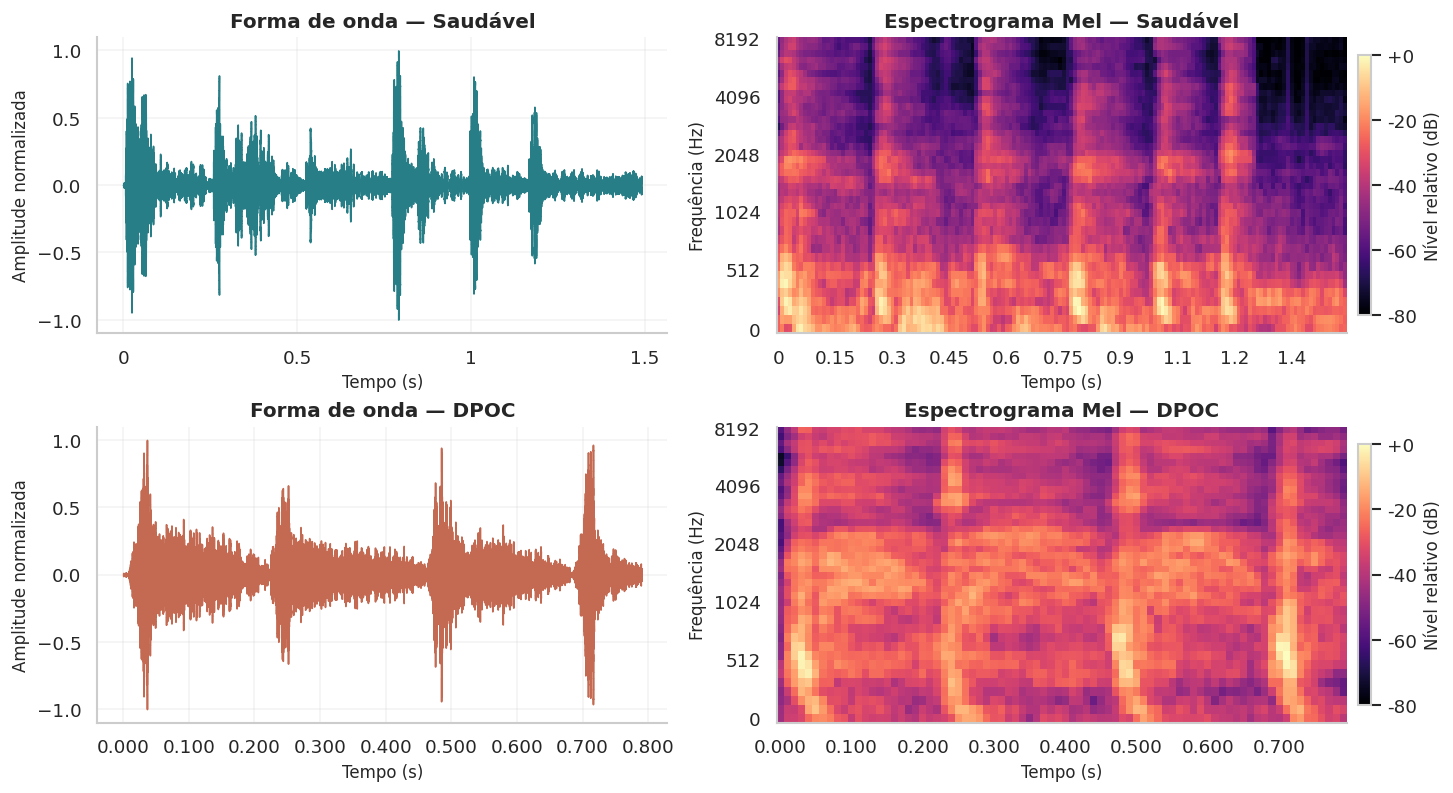

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), constrained_layout=True)
for linha, classe in enumerate(["Saudável", "DPOC"]):
    exemplos = df_dev[df_dev["classe"] == classe]
    exemplo = exemplos.loc[(exemplos["duracao_s"] - exemplos["duracao_s"].median()).abs().idxmin()]
    sinal = carregar_audio(exemplo["arquivo"])

    librosa.display.waveshow(sinal, sr=SR, ax=axes[linha, 0], color=CORES[classe])
    axes[linha, 0].set(title=f"Forma de onda — {classe}", xlabel="Tempo (s)",
                       ylabel="Amplitude normalizada")
    axes[linha, 0].set_ylim(-1.1, 1.1)

    mel = librosa.feature.melspectrogram(y=sinal, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS)
    img = librosa.display.specshow(librosa.power_to_db(mel, ref=np.max), sr=SR,
                                   hop_length=HOP, x_axis="time", y_axis="mel",
                                   cmap="magma", vmin=-80, vmax=0, ax=axes[linha, 1])
    axes[linha, 1].set(title=f"Espectrograma Mel — {classe}",
                       xlabel="Tempo (s)", ylabel="Frequência (Hz)")
    barra = fig.colorbar(img, ax=axes[linha, 1], format="%+d", pad=0.02, shrink=0.88)
    barra.set_label("Nível relativo (dB)")
plt.show()


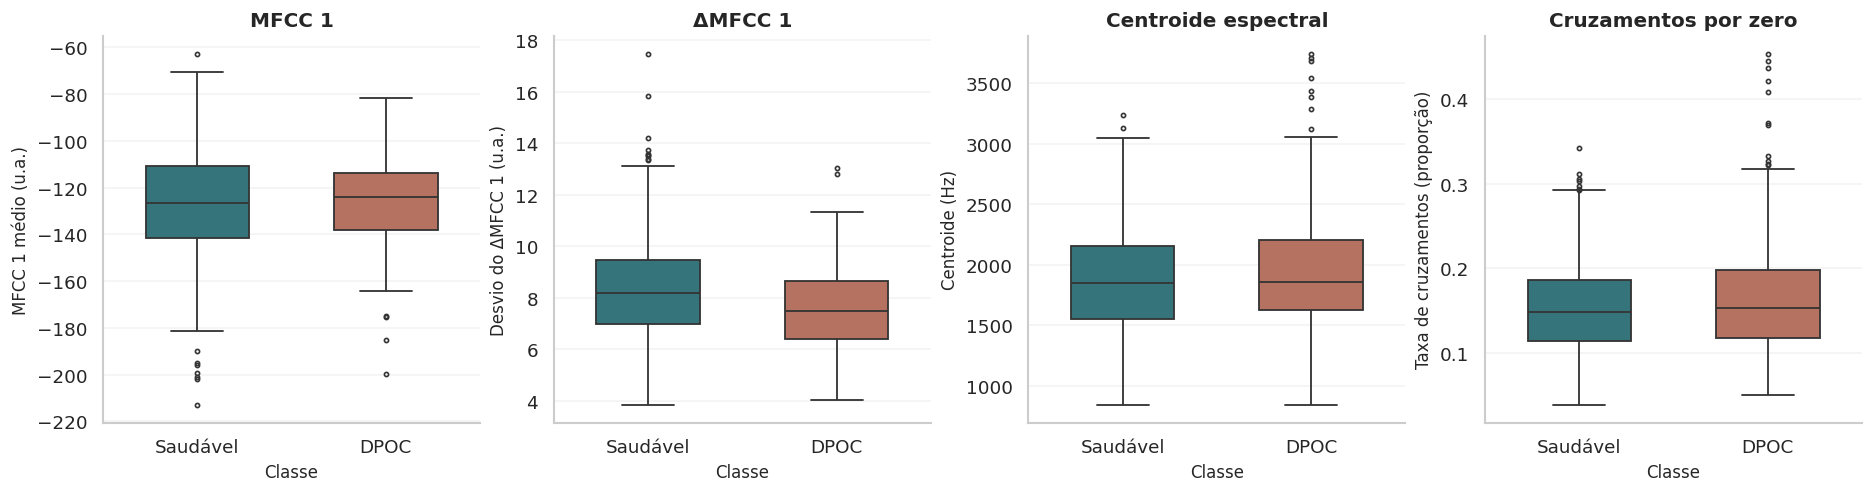

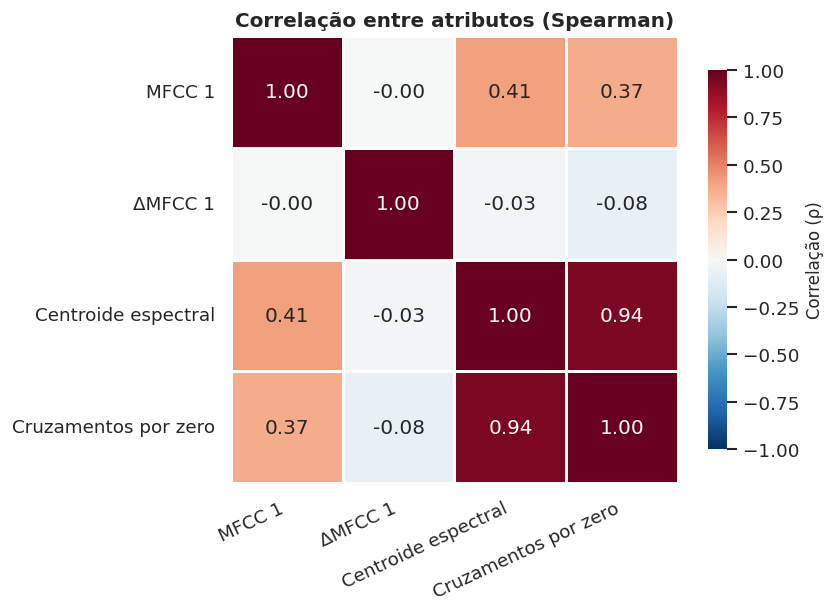

In [20]:
colunas = ["mfcc_1_media", "delta_mfcc_1_desvio", "centroide_media", "zcr_media"]
exploracao = X_dev[colunas].reset_index(drop=True).assign(classe=df_dev["classe"])

nomes_atributos = {
    "mfcc_1_media": ("MFCC 1", "MFCC 1 médio (u.a.)"),
    "delta_mfcc_1_desvio": ("ΔMFCC 1", "Desvio do ΔMFCC 1 (u.a.)"),
    "centroide_media": ("Centroide espectral", "Centroide (Hz)"),
    "zcr_media": ("Cruzamentos por zero", "Taxa de cruzamentos (proporção)"),
}
fig, axes = plt.subplots(1, 4, figsize=(15.5, 4), constrained_layout=True)
for ax, coluna in zip(axes, colunas):
    sns.boxplot(data=exploracao, x="classe", y=coluna, hue="classe",
                order=ORDEM_CLASSES, palette=CORES, legend=False,
                width=0.55, fliersize=2.5, linewidth=1.1, ax=ax)
    titulo, rotulo = nomes_atributos[coluna]
    ax.set(title=titulo, xlabel="Classe", ylabel=rotulo)
plt.show()

correlacoes = X_dev[colunas].corr(method="spearman").rename(
    index={c: nomes_atributos[c][0] for c in colunas},
    columns={c: nomes_atributos[c][0] for c in colunas},
)
fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
sns.heatmap(correlacoes, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.8, linecolor="white",
            cbar_kws={"label": "Correlação (ρ)", "shrink": 0.85}, ax=ax)
ax.set(title="Correlação entre atributos (Spearman)", xlabel="", ylabel="")
ax.tick_params(axis="x", labelrotation=25)
for rotulo in ax.get_xticklabels():
    rotulo.set_ha("right")
ax.tick_params(axis="y", labelrotation=0)
plt.show()


## Treinamento e otimização
Comparam-se SVM padrão e SVM otimizado. A busca avalia 30 configurações de `C`, `gamma` e balanceamento de classes com kernel RBF, usando cinco folds agrupados. A acurácia balanceada orienta a seleção devido ao desbalanceamento. O teste não participa dessa escolha.

In [21]:
%%time
svm = make_pipeline(StandardScaler(), SVC())
busca = RandomizedSearchCV(
    svm,
    {"svc__C": loguniform(0.1, 100), "svc__gamma": loguniform(1e-4, 0.1),
     "svc__class_weight": [None, "balanced"]},
    n_iter=30, scoring="balanced_accuracy", cv=folds,
    random_state=SEMENTE, n_jobs=1, error_score="raise",
)
busca.fit(X_dev, y_dev)
print("Melhores parâmetros:", busca.best_params_)
print(f"Melhor acurácia balanceada na busca: {busca.best_score_:.3f}")

metricas_cv = {"Acurácia balanceada": "balanced_accuracy", "F1 DPOC": "f1", "AUC-ROC": "roc_auc"}
cv_padrao = cross_validate(svm, X_dev, y_dev, cv=folds, scoring=metricas_cv,
                           n_jobs=1, error_score="raise")
melhor = busca.best_index_
resumo_cv = {}
for nome, valores in [("SVM padrão", cv_padrao["test_Acurácia balanceada"]),
                     ("SVM otimizado", np.array([busca.cv_results_[f"split{i}_test_score"][melhor]
                                                 for i in range(len(folds))]))]:
    resumo_cv[nome] = {"Média": valores.mean(), "Desvio entre folds": valores.std(ddof=1)}
display(pd.DataFrame(resumo_cv).T.round(3))
display(pd.DataFrame({m: cv_padrao["test_" + m] for m in metricas_cv},
                     index=range(1, 6)).rename_axis("Fold — SVM padrão").round(3))

Melhores parâmetros: {'svc__C': np.float64(65.41210527692726), 'svc__class_weight': 'balanced', 'svc__gamma': np.float64(0.0003511356313970409)}
Melhor acurácia balanceada na busca: 0.633


,Média,Desvio entre folds
SVM padrão,0.511,0.021
SVM otimizado,0.633,0.061


,Acurácia balanceada,F1 DPOC,AUC-ROC
Fold — SVM padrão,,,
1,0.495,0.053,0.663
2,0.541,0.151,0.614
3,0.507,0.059,0.583
4,0.488,0.059,0.549
5,0.523,0.167,0.685


CPU times: user 5.72 s, sys: 12.4 ms, total: 5.73 s
Wall time: 8.26 s


## Avaliação no teste
DPOC é a classe positiva. **Sensibilidade** mede a proporção de gravações com DPOC reconhecidas corretamente, **especificidade**, a proporção de gravações saudáveis reconhecidas corretamente. Acurácia balanceada, F1 e AUC-ROC complementam a acurácia, especialmente diante do desbalanceamento.

SVM padrão
              precision    recall  f1-score   support

    Saudável       0.76      0.97      0.85       125
        DPOC       0.50      0.09      0.16        43

    accuracy                           0.74       168
   macro avg       0.63      0.53      0.50       168
weighted avg       0.69      0.74      0.67       168

SVM otimizado
              precision    recall  f1-score   support

    Saudável       0.81      0.74      0.77       125
        DPOC       0.39      0.49      0.43        43

    accuracy                           0.67       168
   macro avg       0.60      0.61      0.60       168
weighted avg       0.70      0.67      0.68       168



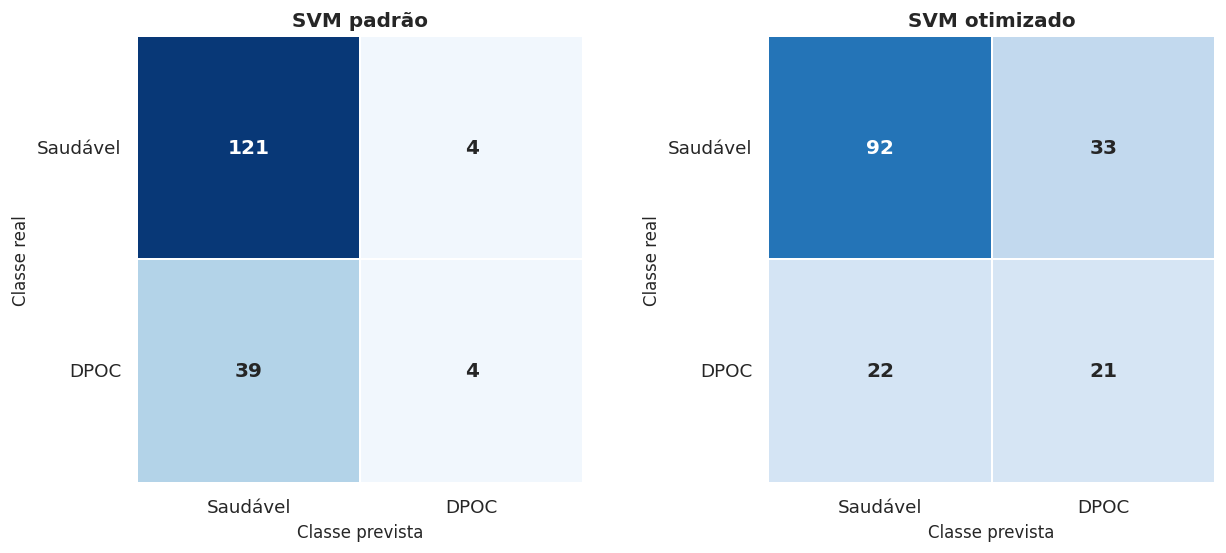

,Acurácia,Acurácia balanceada,Sensibilidade,Especificidade,F1 DPOC,AUC-ROC
SVM padrão,0.744,0.531,0.093,0.968,0.157,0.625
SVM otimizado,0.673,0.612,0.488,0.736,0.433,0.655


Referência sempre saudável: acurácia = 0.744; acurácia balanceada = 0.500


In [22]:
modelos = {"SVM padrão": clone(svm).fit(X_dev, y_dev), "SVM otimizado": busca.best_estimator_}
resultados = {}
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.5), constrained_layout=True)
for ax, (nome, modelo) in zip(axes, modelos.items()):
    previsto = modelo.predict(X_teste)
    pontuacao = modelo.decision_function(X_teste)
    resultados[nome] = {
        "Acurácia": accuracy_score(y_teste, previsto),
        "Acurácia balanceada": balanced_accuracy_score(y_teste, previsto),
        "Sensibilidade": recall_score(y_teste, previsto),
        "Especificidade": recall_score(y_teste, previsto, pos_label=0),
        "F1 DPOC": f1_score(y_teste, previsto, zero_division=0),
        "AUC-ROC": roc_auc_score(y_teste, pontuacao),
    }
    print(nome)
    print(classification_report(y_teste, previsto, labels=[0, 1],
                                target_names=["Saudável", "DPOC"], zero_division=0))
    sns.heatmap(confusion_matrix(y_teste, previsto, labels=[0, 1]), annot=True,
                fmt="d", cmap="Blues", vmin=0, vmax=max(np.bincount(y_teste)),
                cbar=False, square=True, linewidths=1.2, linecolor="white",
                annot_kws={"size": 12, "weight": "semibold"}, ax=ax,
                xticklabels=["Saudável", "DPOC"], yticklabels=["Saudável", "DPOC"])
    ax.set(title=nome, xlabel="Classe prevista", ylabel="Classe real")
    ax.tick_params(axis="x", labelrotation=0)
    ax.tick_params(axis="y", labelrotation=0)
plt.show()
tabela_teste = pd.DataFrame(resultados).T
display(tabela_teste.round(3))
print(f"Referência sempre saudável: acurácia = {(y_teste == 0).mean():.3f}; acurácia balanceada = 0.500")

## Análise e conclusão

A SVM otimizada apresentou melhora na identificação de DPOC, aumentando a sensibilidade de 9,3% para 48,8%, a acurácia balanceada de 53,1% para 61,2% e o F1 de 0,157 para 0,433. A AUC-ROC também aumentou de 0,625 para 0,655. Com isso, o número de gravações de DPOC identificadas corretamente passou de 4 para 21.

Por outro lado, a especificidade diminuiu de 96,8% para 73,6%, e os falsos positivos aumentaram de 4 para 33. A acurácia total também caiu de 74,4% para 67,3%. Como a maioria das gravações é de pessoas saudáveis, a acurácia isolada pode ser enganosa, sendo importante considerar outras métricas.

Apesar da melhora, o modelo otimizado ainda deixou de identificar 22 das 43 gravações de DPOC. Além disso, a avaliação final foi realizada em apenas um conjunto de teste, e diferenças entre os períodos e as condições de coleta podem ter influenciado os resultados. Portanto, o desempenho ainda não é suficiente para recomendar o uso clínico do classificador.